In [124]:
import pandas as pd

df = pd.read_csv('Churn_Modelling.csv')

df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [125]:
df.columns.tolist()

['RowNumber',
 'CustomerId',
 'Surname',
 'CreditScore',
 'Geography',
 'Gender',
 'Age',
 'Tenure',
 'Balance',
 'NumOfProducts',
 'HasCrCard',
 'IsActiveMember',
 'EstimatedSalary',
 'Exited']

In [126]:
print("Quantidade de linhas:", df.shape[0])
print("Quantidade de colunas:", df.shape[1])

Quantidade de linhas: 10000
Quantidade de colunas: 14


In [127]:
print("Quantidade de linhas:", df.shape[0])
print("Quantidade de colunas:", df.shape[1])

Quantidade de linhas: 10000
Quantidade de colunas: 14


In [128]:
df.columns.tolist()

['RowNumber',
 'CustomerId',
 'Surname',
 'CreditScore',
 'Geography',
 'Gender',
 'Age',
 'Tenure',
 'Balance',
 'NumOfProducts',
 'HasCrCard',
 'IsActiveMember',
 'EstimatedSalary',
 'Exited']

In [129]:
df.isnull().sum()

,0
RowNumber,0
CustomerId,0
Surname,0
CreditScore,0
Geography,0
Gender,0
Age,0
Tenure,0
Balance,0
NumOfProducts,0


In [130]:
df.duplicated().sum()

np.int64(0)

In [131]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [132]:
df = df.drop(columns=['RowNumber', 'CustomerId'])

df.columns.tolist()

['Surname',
 'CreditScore',
 'Geography',
 'Gender',
 'Age',
 'Tenure',
 'Balance',
 'NumOfProducts',
 'HasCrCard',
 'IsActiveMember',
 'EstimatedSalary',
 'Exited']

In [133]:
print("Linhas", df.shape[0])
print("Colunas", df.shape[1])

Linhas 10000
Colunas 12


In [134]:
df.to_csv('Churn_Modelling_Limpo.csv', index=False)

In [135]:
# Quantidade de clientes que saíram
clientes_saída = df['Exited'].sum()

# Total de clientes
total_de_clientes = len(df)

#Percentural de churn
percentual_churn = (clientes_saída / total_de_clientes) * 100

print(f"Total de clientes: {total_de_clientes}")
print(f"Clientes que saíram: {clientes_saída}")
print(f"Percentural geral de churn: {percentual_churn:.2f}%")

Total de clientes: 10000
Clientes que saíram: 2037
Percentural geral de churn: 20.37%


In [136]:
# Média de saldo por situação do cliente
saldo=df.groupby('Exited')['Balance'].mean()

print(saldo)

Exited
0    72745.296779
1    91108.539337
Name: Balance, dtype: float64


In [137]:
# Média salarial por situação do cliente
salario=df.groupby('Exited')['EstimatedSalary'].mean()

print(salario)

Exited
0     99738.391772
1    101465.677531
Name: EstimatedSalary, dtype: float64


In [138]:
# Comparação entre clientes que saíram e permaneceram

comparacao=df.groupby('Exited').agg({
    'Balance': ['mean', 'median'],
    'EstimatedSalary': ['mean', 'median'],
    'Exited': 'count'
})

comparacao = comparacao.rename(
    index={
        0:'Permaneceram',
        1:'Saíram'
    }
)

display(comparacao.round(2))

Balance            EstimatedSalary            Exited
                  mean     median            mean     median  count
Exited                                                             
Permaneceram  72745.30   92072.68        99738.39   99645.04   7963
Saíram        91108.54  109349.29       101465.68  102460.84   2037

In [139]:
# Agrupar os clientes por país e calcular a média de Exited
churn_pais=df.groupby('Geography')['Exited'].mean() * 100

# Mostrar os resultados
print(churn_pais.round(2))

Geography
France     16.15
Germany    32.44
Spain      16.67
Name: Exited, dtype: float64


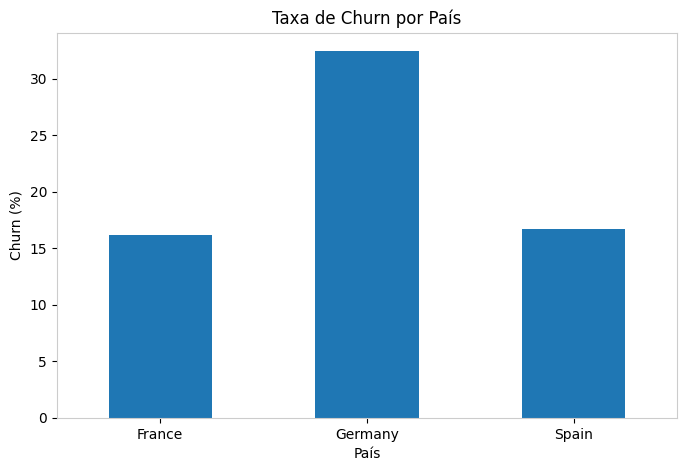

In [140]:
import matplotlib.pyplot as plt

churn_pais.plot(kind='bar', figsize=(8,5))

plt.title('Taxa de Churn por País')
plt.xlabel('País')
plt.ylabel('Churn (%)')
plt.xticks(rotation=0)
plt.show()

In [141]:
# Considerar somente os clientes que saíram
clientes_saida=df[df['Exited']==1]

# Analisar o saldo por país
saldo_pais = clientes_saida.groupby('Geography').agg(
    Quantidade_Clientes=('Exited', 'count'),
    Saldo_Medio=('Balance', 'mean'),
    Saldo_Total=('Balance', 'sum')
)

display(saldo_pais.round(2))

,Quantidade_Clientes,Saldo_Medio,Saldo_Total
Geography,,,
France,810,71192.80,57666164.54
Germany,814,120361.08,97973915.53
Spain,413,72513.35,29948014.56


In [142]:
# Idade média por situação do cliente
idade_media=df.groupby('Exited')['Age'].mean()

print(idade_media.round(2))

Exited
0    37.41
1    44.84
Name: Age, dtype: float64


In [143]:
# Criar faixas etárias
df['Faixa_etaria']=pd.cut(
    df['Age'],
    bins=[0, 25, 35, 45, 55, float('inf')],
    labels=['Até 25', '26-35', '36-45', '46-55', 'Acima de 55']
)
# Calcular o percentual de Churn por faixa etária
churn_idade=df.groupby(
    'Faixa_etaria',
    observed=True
)['Exited'].mean() * 100

print(churn_idade.round(2))

Faixa_etaria
Até 25          7.53
26-35           8.50
36-45          19.62
46-55          50.57
Acima de 55    36.75
Name: Exited, dtype: float64


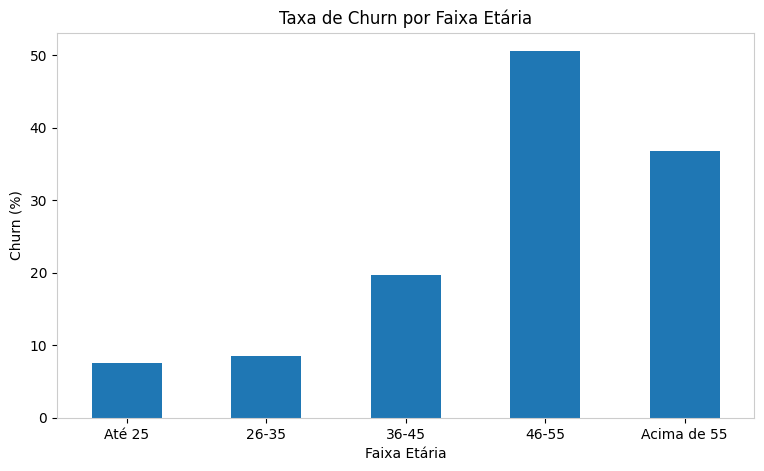

In [144]:
churn_idade.plot(kind='bar', figsize=(9,5))

plt.title('Taxa de Churn por Faixa Etária')
plt.xlabel('Faixa Etária')
plt.ylabel('Churn (%)')
plt.xticks(rotation=0)
plt.show()

In [145]:
# Calcular Churn por gênero
churn_genero = df.groupby('Gender')['Exited'].mean() * 100

print(churn_genero.round(2))

Gender
Female    25.07
Male      16.46
Name: Exited, dtype: float64


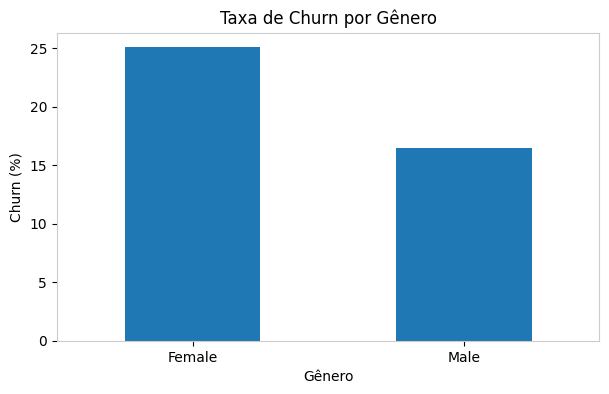

In [146]:
churn_genero.plot(kind='bar', figsize=(7,4))

plt.title('Taxa de Churn por Gênero')
plt.xlabel('Gênero')
plt.ylabel('Churn (%)')
plt.xticks(rotation=0)
plt.show()

In [147]:
# Calcular Churn por tempo de relacionamento
churn_tenure = df.groupby('Tenure')['Exited'].mean() * 100

print(churn_tenure.round(2))

Tenure
0     23.00
1     22.42
2     19.18
3     21.11
4     20.53
5     20.65
6     20.27
7     17.22
8     19.22
9     21.65
10    20.61
Name: Exited, dtype: float64


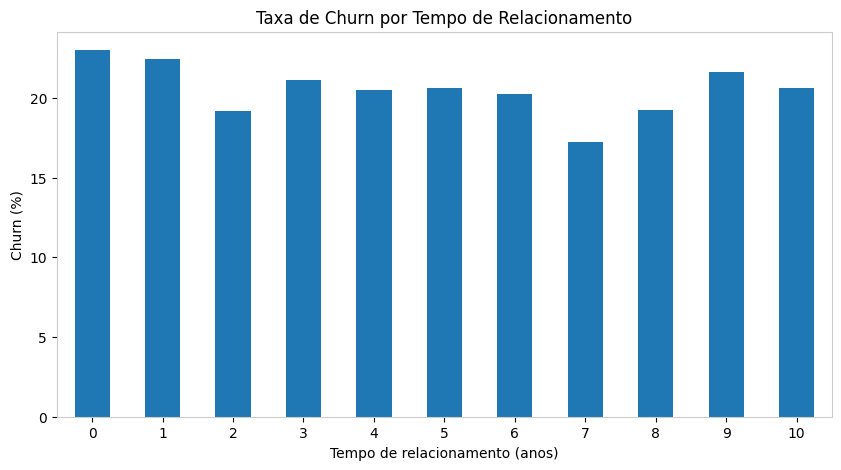

In [148]:
churn_tenure.plot(kind='bar', figsize=(10,5))

plt.title('Taxa de Churn por Tempo de Relacionamento')
plt.xlabel('Tempo de relacionamento (anos)')
plt.ylabel('Churn (%)')
plt.xticks(rotation=0)
plt.show()


In [149]:
# Criar categorias de relacionamento
df['Tempo_Relacionamento'] = pd.cut(
    df['Tenure'],
    bins=[-1, 2, 6, 10],
    labels=['Novos', 'Intermediários', 'Antigos']
)

# Calcular Churn por categoria
churn_tempo = df.groupby(
    'Tempo_Relacionamento',
    observed=True
)['Exited'].mean() * 100

print(churn_tempo.round(2))

Tempo_Relacionamento
Novos             21.15
Intermediários    20.64
Antigos           19.51
Name: Exited, dtype: float64


In [150]:
# Taxa de churn por quantidade de produtos
churn_produtos = df.groupby('NumOfProducts')['Exited'].agg(
    clientes='count',
    churn='mean'
)

churn_produtos['churn_%'] = churn_produtos['churn'] * 100

churn_produtos[['clientes', 'churn_%']].round(2)

,clientes,churn_%
NumOfProducts,,
1,5084,27.71
2,4590,7.58
3,266,82.71
4,60,100.00


In [151]:
# Churn por nível de atividade
churn_atividade = df.groupby('IsActiveMember')['Exited'].agg(
    clientes='count',
    churn='mean'
)

churn_atividade['churn_%'] = churn_atividade['churn'] * 100

print("Churn por atividade:")
display(churn_atividade[['clientes', 'churn_%']].round(2))


# Churn por posse de cartão de crédito
churn_cartao = df.groupby('HasCrCard')['Exited'].agg(
    clientes='count',
    churn='mean'
)

churn_cartao['churn_%'] = churn_cartao['churn'] * 100

print("Churn por cartão de crédito:")
display(churn_cartao[['clientes', 'churn_%']].round(2))

Churn por atividade:


,clientes,churn_%
IsActiveMember,,
0,4849,26.85
1,5151,14.27


Churn por cartão de crédito:


,clientes,churn_%
HasCrCard,,
0,2945,20.81
1,7055,20.18


In [152]:
# Criar faixas de score
df['FaixaScore'] = pd.cut(
    df['CreditScore'],
    bins=[0, 579, 669, 739, 799, 1000],
    labels=['Até 579', '580–669', '670–739', '740–799', '800 ou mais']
)

# Calcular churn por faixa
churn_score = df.groupby('FaixaScore', observed=False)['Exited'].agg(
    clientes='count',
    churn='mean'
)

churn_score['churn_%'] = churn_score['churn'] * 100

churn_score[['clientes', 'churn_%']].round(2)

,clientes,churn_%
FaixaScore,,
Até 579,2362,22.02
580–669,3331,20.56
670–739,2428,18.62
740–799,1224,20.59
800 ou mais,655,19.54


In [153]:
# Filtrar clientes da Alemanha entre 46 e 55 anos
perfil_critico = df[
    (df['Geography'] == 'Germany') &
    (df['Age'].between(46, 55))
].copy()

print("Total de clientes no perfil crítico:", len(perfil_critico))

# Churn por quantidade de produtos nesse perfil
critico_produtos = perfil_critico.groupby('NumOfProducts')['Exited'].agg(
    clientes='count',
    churn='mean'
)

critico_produtos['churn_%'] = critico_produtos['churn'] * 100

display(critico_produtos[['clientes', 'churn_%']].round(2))

Total de clientes no perfil crítico: 403


,clientes,churn_%
NumOfProducts,,
1,265,76.98
2,109,33.94
3,22,100.00
4,7,100.00


In [154]:
# Churn por atividade no perfil crítico
display(
    perfil_critico.groupby('IsActiveMember')['Exited']
    .agg(clientes='count', churn='mean')
    .assign(churn_pct=lambda x: x['churn'] * 100)
    [['clientes', 'churn_pct']]
    .round(2)
)

# Churn por cartão no perfil crítico
display(
    perfil_critico.groupby('HasCrCard')['Exited']
    .agg(clientes='count', churn='mean')
    .assign(churn_pct=lambda x: x['churn'] * 100)
    [['clientes', 'churn_pct']]
    .round(2)
)

,clientes,churn_pct
IsActiveMember,,
0,225,77.33
1,178,53.93


,clientes,churn_pct
HasCrCard,,
0,115,72.17
1,288,64.93


In [155]:
# Cruzamento entre produtos e atividade no perfil crítico
cruzamento_critico = perfil_critico.pivot_table(
    index='NumOfProducts',
    columns='IsActiveMember',
    values='Exited',
    aggfunc=['count', 'mean'],
    observed=False
)

display(cruzamento_critico.round(3))

count        mean       
IsActiveMember     0    1      0      1
NumOfProducts                          
1                154  111  0.870  0.631
2                 53   56  0.415  0.268
3                 15    7  1.000  1.000
4                  3    4  1.000  1.000

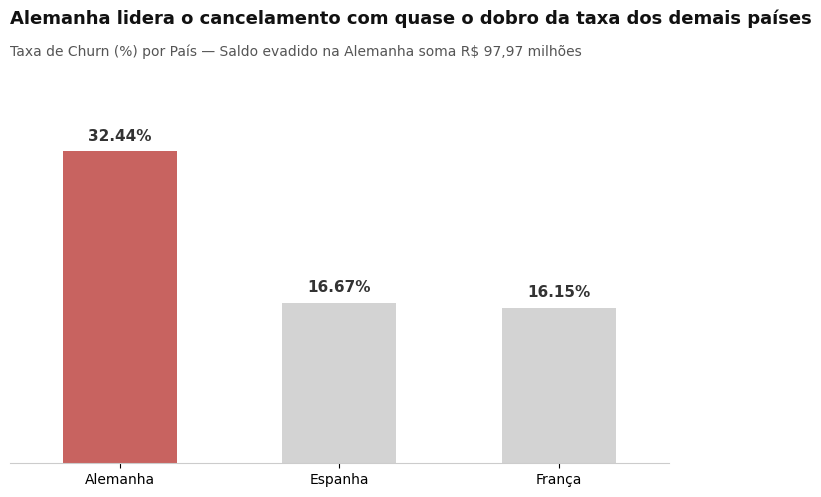

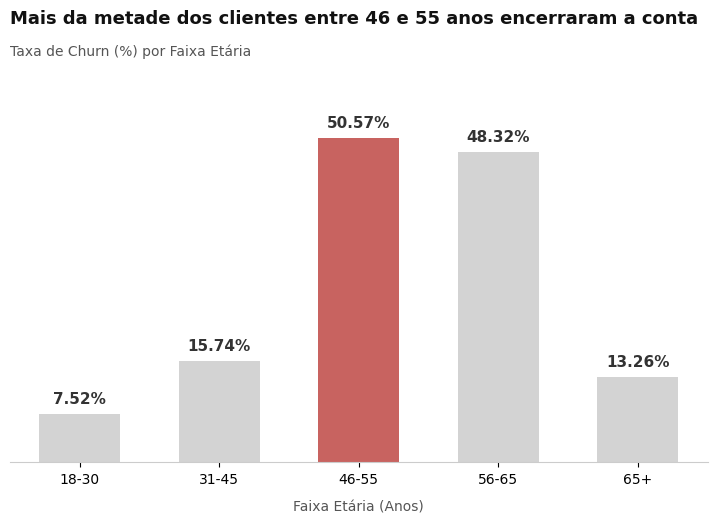

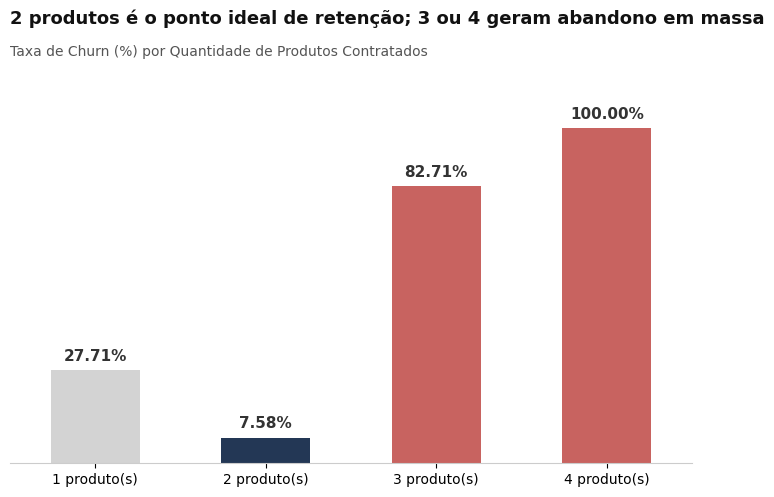

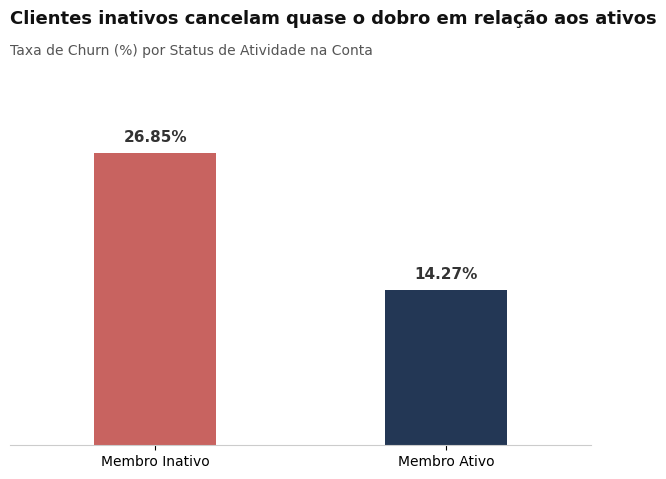

In [156]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#CCCCCC'
plt.rcParams['axes.linewidth'] = 0.8

COR_DESTAQUE = '#D9534F'
COR_RETENCAO = '#1B365D'
COR_NEUTRA   = '#D3D3D3'

def adicionar_rotulos(ax, formato='{:.2f}%', offset=1.2):
    for p in ax.patches:
        altura = p.get_height()
        if not np.isnan(altura) and altura > 0:
            ax.annotate(
                formato.format(altura),
                (p.get_x() + p.get_width() / 2., altura + offset),
                ha='center', va='bottom',
                fontsize=11, fontweight='bold', color='#333333'
            )

def aplicar_cabecalho(ax, titulo, subtitulo):
    ax.text(0, 1.13, titulo, transform=ax.transAxes,
            fontsize=13, fontweight='bold', color='#111111', ha='left', va='bottom')
    ax.text(0, 1.05, subtitulo, transform=ax.transAxes,
            fontsize=10, color='#555555', ha='left', va='bottom')

# ==============================================================================
# GRÁFICO 1: Taxa de Churn por País
# ==============================================================================
fig, ax = plt.subplots(figsize=(8.5, 5))

churn_pais = (df.groupby('Geography')['Exited'].mean() * 100).sort_values(ascending=False).reset_index()
churn_pais['Geography'] = churn_pais['Geography'].replace({'Germany': 'Alemanha', 'Spain': 'Espanha', 'France': 'França'})
cores_pais = [COR_DESTAQUE if x == 'Alemanha' else COR_NEUTRA for x in churn_pais['Geography']]

sns.barplot(data=churn_pais, x='Geography', y='Exited', hue='Geography', palette=cores_pais, legend=False, ax=ax, width=0.52)
adicionar_rotulos(ax, offset=0.8)
aplicar_cabecalho(
    ax,
    'Alemanha lidera o cancelamento com quase o dobro da taxa dos demais países',
    'Taxa de Churn (%) por País — Saldo evadido na Alemanha soma R$ 97,97 milhões'
)

ax.set_xlabel('')
ax.set_ylabel('')
ax.set_ylim(0, 40)
ax.yaxis.set_visible(False)
sns.despine(left=True, top=True, right=True)

plt.savefig('1_churn_por_pais.png', dpi=300, bbox_inches='tight', pad_inches=0.25)
plt.show()

# ==============================================================================
# GRÁFICO 2: Taxa de Churn por Faixa Etária
# ==============================================================================
fig, ax = plt.subplots(figsize=(9, 5))

bins = [17, 30, 45, 55, 65, 100]
labels = ['18-30', '31-45', '46-55', '56-65', '65+']
df['Faixa_Etaria'] = pd.cut(df['Age'], bins=bins, labels=labels)

churn_idade = (df.groupby('Faixa_Etaria', observed=False)['Exited'].mean() * 100).reset_index()
cores_idade = [COR_DESTAQUE if x == '46-55' else COR_NEUTRA for x in churn_idade['Faixa_Etaria']]

sns.barplot(data=churn_idade, x='Faixa_Etaria', y='Exited', hue='Faixa_Etaria', palette=cores_idade, legend=False, ax=ax, width=0.58)
adicionar_rotulos(ax, offset=1.2)
aplicar_cabecalho(
    ax,
    'Mais da metade dos clientes entre 46 e 55 anos encerraram a conta',
    'Taxa de Churn (%) por Faixa Etária'
)

ax.set_xlabel('Faixa Etária (Anos)', fontsize=10, color='#555555', labelpad=10)
ax.set_ylabel('')
ax.set_ylim(0, 60)
ax.yaxis.set_visible(False)
sns.despine(left=True, top=True, right=True)

plt.savefig('2_churn_por_idade.png', dpi=300, bbox_inches='tight', pad_inches=0.25)
plt.show()

# ==============================================================================
# GRÁFICO 3: Quantidade de Produtos
# ==============================================================================
fig, ax = plt.subplots(figsize=(8.8, 5))

churn_prod = (df.groupby('NumOfProducts')['Exited'].mean() * 100).reset_index()
churn_prod['Label'] = churn_prod['NumOfProducts'].astype(str) + ' produto(s)'

cores_prod = [
    COR_RETENCAO if n == 2 else (COR_DESTAQUE if n in [3, 4] else COR_NEUTRA)
    for n in churn_prod['NumOfProducts']
]

sns.barplot(data=churn_prod, x='Label', y='Exited', hue='Label', palette=cores_prod, legend=False, ax=ax, width=0.52)
adicionar_rotulos(ax, offset=2.0)
aplicar_cabecalho(
    ax,
    '2 produtos é o ponto ideal de retenção; 3 ou 4 geram abandono em massa',
    'Taxa de Churn (%) por Quantidade de Produtos Contratados'
)

ax.set_xlabel('')
ax.set_ylabel('')
ax.set_ylim(0, 115)
ax.yaxis.set_visible(False)
sns.despine(left=True, top=True, right=True)

plt.savefig('3_churn_por_produtos.png', dpi=300, bbox_inches='tight', pad_inches=0.25)
plt.show()

# ==============================================================================
# GRÁFICO 4: Engajamento (Ativos vs. Inativos)
# ==============================================================================
fig, ax = plt.subplots(figsize=(7.5, 4.8))

churn_ativo = (df.groupby('IsActiveMember')['Exited'].mean() * 100).reset_index()
churn_ativo['Status'] = churn_ativo['IsActiveMember'].map({0: 'Membro Inativo', 1: 'Membro Ativo'})
churn_ativo = churn_ativo.sort_values(by='Exited', ascending=False)
cores_ativo = [COR_DESTAQUE, COR_RETENCAO]

sns.barplot(data=churn_ativo, x='Status', y='Exited', hue='Status', palette=cores_ativo, legend=False, ax=ax, width=0.42)
adicionar_rotulos(ax, offset=0.8)
aplicar_cabecalho(
    ax,
    'Clientes inativos cancelam quase o dobro em relação aos ativos',
    'Taxa de Churn (%) por Status de Atividade na Conta'
)

ax.set_xlabel('')
ax.set_ylabel('')
ax.set_ylim(0, 34)
ax.yaxis.set_visible(False)
sns.despine(left=True, top=True, right=True)

plt.savefig('4_churn_engajamento.png', dpi=300, bbox_inches='tight', pad_inches=0.25)
plt.show()